# Regenerate thesis plots

Run all cells from `experiments/` using the repository's virtual environment. This notebook loads the existing likelihood and judge SQLite caches **once at the beginning**; it does not read judge CSVs or run model inference. It exports every data-driven figure referenced by `thesis/main.typ` (including the appendix) to `thesis/figures/`. The introduction and methods diagrams are edited separately in their `.drawio` files.

The broken BIG-Bench Mistake Dyck trace (UID 52) is excluded throughout. Context relevance uses average token log likelihood in each context. The comparison thresholds for `judge-vs-context-overall.png` are tuned and evaluated on the same traces (optimistic); tracking uses five-fold out-of-fold thresholds.

## Load data from caches

Load benchmark examples, likelihood scores, and judge responses once for all five models. Every plot below reuses these in-memory tables.

In [1]:
from pathlib import Path
from dotenv import load_dotenv

# Hugging Face datasets are fetched by load_examples() in the next cell.
load_dotenv(Path.cwd().parent / 'secret.env')

True

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns
from seaborn.algorithms import bootstrap
from scipy.stats import mannwhitneyu
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn.model_selection import StratifiedKFold, TunedThresholdClassifierCV

EXPERIMENTS = Path.cwd()
assert (EXPERIMENTS / 'experiment_setup').is_dir(), 'Run with experiments/ as working directory'
sys.path.insert(0, str(EXPERIMENTS))
from experiment_setup import dc_pmi, llm_critic
from experiment_setup.benchmarks import load_examples, sample_control_and_error
from experiment_setup.judge_metrics import score as judge_score, summarize, processbench_average

CACHE = EXPERIMENTS / 'cache'
OUT = EXPERIMENTS.parent / 'thesis/figures'
OUT.mkdir(parents=True, exist_ok=True)
MODELS = {
    'Qwen3.5-4B': ('Qwen/Qwen3.5-4B', 'qwen35_4b'),
    'Qwen3.5-9B': ('Qwen/Qwen3.5-9B', 'qwen35_9b'),
    'Qwen3.5-27B': ('Qwen/Qwen3.5-27B', 'qwen35_27b'),
    'Llama3.1-8B': ('meta-llama/Llama-3.1-8B-Instruct', 'llama31_8b'),
    'Llama3.2-3B': ('meta-llama/Llama-3.2-3B-Instruct', 'llama32_3b'),
}
BENCHMARKS = ['MR-GSM8K', 'BIG-Bench-Mistake', 'ProcessBench']
KEYS = ['benchmark', 'task', 'uid']
examples = [e for task in load_examples().values() for e in task
            if not (e.benchmark == 'BIG-Bench-Mistake' and e.task == 'dyck_languages' and e.uid == '52')]
assert len(examples) == 8584
expected = pd.DataFrame([dict(benchmark=e.benchmark, task=e.task, uid=str(e.uid), label=e.label)
                         for e in examples])
assert not expected.duplicated(KEYS).any()

# Load each model's likelihood and judge responses from SQLite exactly once.
scores_by_model = {}
judges_by_model = {}
for model, (model_id, stem) in MODELS.items():
    scores = dc_pmi.load_run(examples, model_id=model_id, average_ll=True,
                             cache_path=CACHE / f'dc_pmi_{stem}_arm.sqlite')
    scores['uid'] = scores.uid.astype(str)
    assert len(scores[KEYS].drop_duplicates()) == len(examples)
    scores_by_model[model] = scores

    judge = llm_critic.load_run(examples, model_id=model_id,
                                cache_path=CACHE / f'llm_judge_{stem}_arm.sqlite')
    judge['uid'] = judge.uid.astype(str)
    judge = expected[KEYS].merge(judge, on=KEYS, how='left', validate='one_to_one', indicator=True)
    assert judge._merge.eq('both').all(), model
    assert judge.label.fillna(-1).eq(expected.label.fillna(-1)).all(), model
    judges_by_model[model] = judge.drop(columns=['_merge', 'transcript', 'cache_key'])

print(f'Loaded {len(examples)} traces for each of {len(MODELS)} models (cache-only).')

In [18]:
# Plot style: edit these values, then rerun this cell and the desired plot cells.
TEXT_SIZE = 16
COLORS = dict(zip(MODELS, ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']))
METHOD_COLORS = [COLORS['Qwen3.5-4B'], COLORS['Qwen3.5-9B']]
PAPER_COLOR = '#888888'
OUR_PAPER_COLOR = COLORS['Qwen3.5-4B']
HEATMAP_NEUTRAL = '#E5E5E5'

plt.rcParams.update({
    'font.size': TEXT_SIZE,
    'axes.labelsize': TEXT_SIZE,
    'xtick.labelsize': TEXT_SIZE,
    'ytick.labelsize': TEXT_SIZE,
    'legend.fontsize': TEXT_SIZE,
    'legend.title_fontsize': TEXT_SIZE,
    'figure.titlesize': TEXT_SIZE,
    'axes.titlesize': TEXT_SIZE,
})

## Compute plot data

Run these cells after loading the caches. All benchmark scoring, summaries, threshold tuning, and trajectory matching happen here; the plotting cells below only render the prepared results.

In [ ]:
# Fully ablated CR: pooled AUROC by benchmark and model.
cr_auc_rows = []
for benchmark in BENCHMARKS:
    for model, scores in scores_by_model.items():
        group = scores.loc[scores.benchmark == benchmark]
        evidence = dc_pmi.error_evidence_score(group, 'dc_pmi_generic_domain')
        auc = roc_auc_score(group.first_error, evidence)
        p_value = mannwhitneyu(evidence.loc[group.first_error],
                                evidence.loc[~group.first_error], alternative='greater').pvalue
        cr_auc_rows.append(dict(benchmark=benchmark, model=model, auc=auc, p_value=p_value))
cr_auc = pd.DataFrame(cr_auc_rows)

# Same first-error AUROC, split by benchmark task.
stats = pd.concat([dc_pmi.statistics(scores).assign(model=model)
                   for model, scores in scores_by_model.items()], ignore_index=True)
task_order = list(stats[['benchmark', 'task']].drop_duplicates().itertuples(index=False, name=None))
task_labels = [b.replace('BIG-Bench-Mistake', 'BBM').replace('MR-GSM8K', 'MR').replace('ProcessBench', 'PB')
               + ' / ' + t.replace('_', ' ') for b, t in task_order]
subset = stats.loc[stats.metric == 'dc_pmi_generic_domain'].copy()
subset['task_label'] = (subset.benchmark.str.replace('BIG-Bench-Mistake', 'BBM', regex=False)
                        .str.replace('MR-GSM8K', 'MR', regex=False)
                        .str.replace('ProcessBench', 'PB', regex=False)
                        + ' / ' + subset.task.str.replace('_', ' '))
cr_task_grid = (subset.pivot(index='model', columns='task_label', values='auc')
                .reindex(index=list(MODELS), columns=task_labels))

# Judge accuracy and published baselines.
overview = pd.concat([summarize(frame).assign(model=model)
                      for model, frame in judges_by_model.items()], ignore_index=True)
overview['benchmark'] = pd.Categorical(overview.benchmark, BENCHMARKS, ordered=True)
overview['model'] = pd.Categorical(overview.model, list(MODELS), ordered=True)
overview = overview.sort_values(['benchmark', 'model'])

# Paper values from Zheng et al. (2025), Table 3 Average; Zeng et al. (2023),
# Table 2 zero-shot Task 1 MCC; Tyen et al. (2024), Table 4 Overall/Direct.
pb_paper = {
    'Meta-Llama-3-8B-Instruct': 11.1, 'Meta-Llama-3-70B-Instruct': 29.1,
    'Llama-3.1-8B-Instruct': 5.1, 'Llama-3.1-70B-Instruct': 52.7,
    'Llama-3.3-70B-Instruct': 58.0, 'Qwen2.5-Math-7B-Instruct': 19.9,
    'Qwen2.5-Math-72B-Instruct': 45.5, 'Qwen2.5-Coder-7B-Instruct': 6.7,
    'Qwen2.5-Coder-14B-Instruct': 37.8, 'Qwen2.5-Coder-32B-Instruct': 56.1,
    'Qwen2-7B-Instruct': 13.6, 'Qwen2-72B-Instruct': 49.8,
    'Qwen2.5-7B-Instruct': 32.6, 'Qwen2.5-14B-Instruct': 52.2,
    'Qwen2.5-32B-Instruct': 49.3, 'Qwen2.5-72B-Instruct': 61.2,
    'QwQ-32B-Preview': 71.5,
}
mr_paper = {
    'Qwen-1.8B': 0.0, 'Phi3-3.8B': 20.4, 'Deepseek-Math-7B-RL': 30.4,
    'WizardMath-v1.1-7B': 0.0, 'Llama3-8B': 5.1, 'MAmmoTH-70B': 14.6,
    'MetaMath-70B': 0.0, 'Llama3-70B': 51.3, 'Qwen1.5-72B': 42.0,
    'Deepseek-v2-236B': 49.4, 'Claude3-Haiku': 22.5,
    'GPT-3.5-Turbo': 16.2, 'Claude3-Sonnet': 30.0, 'GPT-4-Turbo': 63.3,
}
bbm_paper = {
    'GPT-4-Turbo': 30.13, 'GPT-4': 39.80, 'GPT-3.5-Turbo': 10.44,
    'Gemini Pro': 16.14, 'PaLM 2 Unicorn': 17.09,
}
pb_ours = {model: processbench_average(frame) * 100 for model, frame in judges_by_model.items()}
mr_ours = overview[overview.benchmark == 'MR-GSM8K'].set_index('model')
mr_paper_scaled = {name: value / 100 for name, value in mr_paper.items()}
mr_ours_mcc = {model: mr_ours.loc[model, 'mr_mcc'] for model in MODELS}
bbm_ours = {model: summarize(frame[frame.benchmark == 'BIG-Bench-Mistake'],
                             ('task',)).accuracy.mean() * 100
            for model, frame in judges_by_model.items()}
print('Computed context-relevance AUROCs and judge/published-baseline summaries.')

In [4]:
# Exact first-error-or-NONE accuracy and threshold tuning.
def exact_location_accuracy(y_true, y_pred, *, candidate_correct):
    predicted_error = np.asarray(y_pred, dtype=bool)
    actual_error = np.asarray(y_true, dtype=bool)
    return np.mean((~predicted_error & ~actual_error) |
                   (predicted_error & candidate_correct))


def select_candidates(scores, metric):
    evidence = dc_pmi.error_evidence_score(scores, metric)
    candidates = scores.assign(evidence=evidence).loc[
        evidence.groupby([scores[k] for k in KEYS], sort=False).idxmax()
    ].copy()
    candidates['candidate_correct'] = candidates.step.eq(candidates.label)
    return candidates


def tune_accuracy(candidates):
    evidence = candidates.evidence.to_numpy()
    truth = candidates.label.notna().to_numpy()
    X = evidence.reshape(-1, 1)
    thresholds = np.unique(np.r_[np.nextafter(evidence.min(), -np.inf), evidence,
                                 np.nextafter(evidence.max(), np.inf)])
    estimator = dc_pmi.RawScoreClassifier().fit(X, truth)
    tuned = TunedThresholdClassifierCV(
        estimator, cv='prefit', refit=False, response_method='decision_function',
        scoring=make_scorer(exact_location_accuracy,
                            candidate_correct=candidates.candidate_correct.to_numpy(dtype=bool)),
        thresholds=thresholds,
    ).fit(X, truth)
    return tuned.best_score_, tuned.best_threshold_


# Judge vs fully ablated CR on the same traces. Threshold tuning and evaluation
# use the same data (optimistic in-sample accuracy, not held-out performance).
comparison_rows = []
for model, scores in scores_by_model.items():
    judge = judges_by_model[model]
    for benchmark in BENCHMARKS:
        judge_group = judge.loc[judge.benchmark == benchmark]
        judge_result = judge_score(judge_group)
        comparison_rows.append(dict(benchmark=benchmark, model=model, method='LLM judge',
                                    error_accuracy=judge_result['error_accuracy'],
                                    overall_accuracy=judge_result['accuracy']))
        candidates = select_candidates(scores.loc[scores.benchmark == benchmark],
                                       'dc_pmi_generic_domain')
        assert len(candidates) == len(judge_group)
        accuracy, threshold = tune_accuracy(candidates)
        comparison_rows.append(dict(benchmark=benchmark, model=model,
                                    method='Fully ablated context relevance',
                                    error_accuracy=candidates.loc[candidates.label.notna(),
                                                                  'candidate_correct'].mean(),
                                    overall_accuracy=accuracy))
comparison = pd.DataFrame(comparison_rows)
methods = ['LLM judge', 'Fully ablated context relevance']
comparison_bars = {}
for column in ['error_accuracy', 'overall_accuracy']:
    for benchmark in BENCHMARKS:
        comparison_bars[column, benchmark] = (comparison.loc[comparison.benchmark == benchmark]
                                              .pivot(index='model', columns='method', values=column)
                                              .reindex(index=MODELS, columns=methods).mul(100))
print('Computed judge-versus-context accuracy comparisons.')

Computed judge-versus-context accuracy comparisons.


In [5]:
# BIG-Bench Mistake / tracking shuffled objects: the same 300 traces and
# average-token-LL scores as shuffled-objects-task.ipynb.
tracking = expected.loc[(expected.benchmark == 'BIG-Bench-Mistake') &
                        (expected.task == 'tracking_shuffled_objects')].copy()
assert len(tracking) == 300
bar_methods = {
    'perplexity': 'Perplexity',
    'dc_pmi_generic_domain': 'Negative fully ablated CR',
    'dc_pmi_question_ablation': 'Negative question-ablated CR',
    'dc_pmi_history_ablation': 'Negative history-ablated CR',
}
bar_rows = []
for model, scores in scores_by_model.items():
    group = scores.loc[(scores.benchmark == 'BIG-Bench-Mistake') &
                       (scores.task == 'tracking_shuffled_objects')]
    for metric, label in bar_methods.items():
        evidence = dc_pmi.error_evidence_score(group, metric)
        bar_rows.append(dict(model=model, method=label,
                             auroc=roc_auc_score(group.first_error, evidence)))
bar_results = pd.DataFrame(bar_rows)

# Five-fold out-of-fold threshold for negative question-ablated CR, as in the
# exploration notebook; LLM judges use their cached, unparseable-inclusive scores.
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(
    tracking, tracking.label.notna()))
accuracy_rows = []
for model, scores in scores_by_model.items():
    group = scores.loc[(scores.benchmark == 'BIG-Bench-Mistake') &
                       (scores.task == 'tracking_shuffled_objects')]
    candidates = tracking[KEYS].merge(select_candidates(group, 'dc_pmi_question_ablation'),
                                      on=KEYS, how='left', validate='one_to_one', indicator=True)
    assert candidates._merge.eq('both').all()
    assert candidates.label.fillna(-1).eq(tracking.label.to_numpy(na_value=-1)).all()
    predictions = np.full(len(candidates), np.nan)
    for train_idx, test_idx in folds:
        _, threshold = tune_accuracy(candidates.iloc[train_idx])
        test = candidates.iloc[test_idx]
        predictions[test_idx] = np.where(test.evidence.ge(threshold), test.step, -1)
    assert np.isfinite(predictions).all()
    accuracy_rows.append(dict(model=model, method='Negative question-ablated CR (5-fold CV)',
                              accuracy=np.mean(predictions == candidates.label.fillna(-1).to_numpy())))
    judge = judges_by_model[model]
    judge = judge.loc[(judge.benchmark == 'BIG-Bench-Mistake') &
                      (judge.task == 'tracking_shuffled_objects')]
    assert len(judge) == len(tracking)
    accuracy_rows.append(dict(model=model, method='LLM judge',
                              accuracy=judge_score(judge)['accuracy']))
accuracy_table = pd.DataFrame(accuracy_rows)
tracking_clean_percent = 100 * tracking.label.isna().mean()
print('Computed tracking-shuffled-objects AUROC and cross-validated accuracy.')

Computed tracking-shuffled-objects AUROC and cross-validated accuracy.


In [6]:
# Appendix: align each annotated error with a distinct clean trace of the
# same task and length; anchor the clean trace at its paired error step index.
error_examples, control_examples = sample_control_and_error(examples, seed=42)
assert len(error_examples) == len(control_examples) > 0
assert all((e.benchmark, e.task, len(e.steps)) == (c.benchmark, c.task, len(c.steps))
           for e, c in zip(error_examples, control_examples))
all_scores = pd.concat([scores.assign(uid=model + ':' + scores.uid)
                        for model, scores in scores_by_model.items()], ignore_index=True)
error_keys = pd.DataFrame([
    dict(benchmark=e.benchmark, task=e.task, uid=f'{model}:{e.uid}', n_steps=len(e.steps))
    for e in error_examples for model in MODELS
])
control_anchors = pd.DataFrame([
    dict(benchmark=c.benchmark, task=c.task, uid=f'{model}:{c.uid}',
         anchor=e.label, n_steps=len(c.steps))
    for e, c in zip(error_examples, control_examples) for model in MODELS
])
error_scores = all_scores.merge(error_keys, on=KEYS, how='inner', validate='many_to_one')
control_scores = all_scores.merge(control_anchors, on=KEYS, how='inner', validate='many_to_one')
assert error_scores[KEYS].drop_duplicates().shape[0] == len(error_examples) * len(MODELS)
assert control_scores[KEYS].drop_duplicates().shape[0] == len(control_examples) * len(MODELS)
assert error_scores.groupby(KEYS).size().eq(error_scores.groupby(KEYS).n_steps.first()).all()
assert control_scores.groupby(KEYS).size().eq(control_scores.groupby(KEYS).n_steps.first()).all()
control_scores['first_error'] = control_scores.step.eq(control_scores.anchor)
assert control_scores.groupby(KEYS).first_error.sum().eq(1).all()
assert error_scores.groupby(KEYS).first_error.sum().eq(1).all()


def trajectory_summary(scores, window=5):
    """Align traces and bootstrap mean/95% CI at each offset once, before plotting."""
    traces = []
    for (benchmark, task, uid), group in scores.groupby(KEYS, sort=False):
        errors = group.loc[group.first_error]
        if errors.empty:
            continue
        assert len(errors) == 1, f'Expected one first error for {benchmark}/{task}/{uid}'
        trace = group.copy()
        trace['offset'] = trace.step - errors.iloc[0].step
        traces.append(trace[trace.offset.between(-window, window)])
    assert traces, 'No annotated first-error traces to plot'
    aligned = pd.concat(traces, ignore_index=True)
    rows = []
    for metric in dc_pmi.METRICS:
        for offset, group in aligned.groupby('offset', sort=True):
            values = group[metric].dropna().to_numpy()
            mean = values.mean()
            ci_low, ci_high = (np.percentile(bootstrap(values, func='mean', seed=42), [2.5, 97.5])
                               if len(values) > 1 else (np.nan, np.nan))
            rows.append(dict(metric=metric, offset=offset, mean=mean,
                             ci_low=ci_low, ci_high=ci_high))
    return pd.DataFrame(rows)


trajectory_summaries = {
    'trajectory.png': trajectory_summary(error_scores),
    'trajectory-control.png': trajectory_summary(control_scores),
}
print('Prepared and bootstrapped matched error/control trajectories.')

Prepared and bootstrapped matched error/control trajectories.


## Context relevance: first-error AUROC

Plot pooled benchmark-level AUROC and task-level AUROC for fully ablated context relevance. Lower scores indicate stronger error evidence; the significance test is one-sided and unadjusted.

In [ ]:
# Fully ablated CR: pooled AUROC by benchmark and model.
bar_width = 0.16
fig, ax = plt.subplots(figsize=(18, 8))
for row in cr_auc.itertuples(index=False):
    benchmark_index = BENCHMARKS.index(row.benchmark)
    model_index = list(MODELS).index(row.model)
    x = benchmark_index + (model_index - (len(MODELS) - 1) / 2) * bar_width
    bar = ax.bar(x, row.auc, width=bar_width * .9, color=COLORS[row.model],
                 alpha=.35 if row.p_value >= .05 else 1)
    ax.bar_label(bar, labels=[f'{row.auc:.3f}\n{row.p_value:.0e}'], padding=3,
                 fontsize=TEXT_SIZE, clip_on=False)
ax.axhline(.5, color='black', linestyle='--', linewidth=1, alpha=.5)
ax.set(xticks=range(len(BENCHMARKS)), xticklabels=BENCHMARKS,
       ylabel='First-error AUROC', ylim=(0, 1))
ax.margins(x=.08)
ax.tick_params(axis='both', labelsize=TEXT_SIZE)
ax.grid(axis='y', alpha=.2)
fig.legend(handles=[Patch(color=COLORS[model], label=model) for model in MODELS],
           loc='upper right', bbox_to_anchor=(.99, .99), ncol=5, fontsize=TEXT_SIZE)
fig.tight_layout(rect=(0, 0, 1, .88))
fig.savefig(OUT / 'fully-ablated-cr-comparison.png', dpi=220, bbox_inches='tight')
display(fig)
plt.close(fig)

# Same first-error AUROC, split by benchmark task.
fig, ax = plt.subplots(figsize=(22, 7), constrained_layout=True)
sns.heatmap(cr_task_grid, ax=ax, annot=True, fmt='.2f',
            cmap=sns.blend_palette([COLORS['Qwen3.5-9B'], HEATMAP_NEUTRAL,
                                   COLORS['Qwen3.5-4B']], as_cmap=True),
            vmin=.35, vmax=.95, center=.5,
            cbar_kws={'label': 'First-error AUROC'}, linewidths=.4,
            annot_kws={'fontsize': TEXT_SIZE})
ax.set(xlabel='Task type', ylabel='Model')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=TEXT_SIZE)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=TEXT_SIZE)
fig.savefig(OUT / 'task-method-auroc.png', dpi=220, bbox_inches='tight')
display(fig)
plt.close(fig)
print('Exported fully-ablated-cr-comparison.png and task-method-auroc.png')

## LLM judge and published baselines

Compare cached judge responses against the published ProcessBench, MR-GSM8K, and BIG-Bench Mistake results. The published values use different models and protocols, so these are contextual comparisons, not replications.

In [ ]:
def paper_comparison(paper, ours, source, metric, filename, max_y=100, height=9):
    values = pd.Series(paper | ours).sort_values(kind='stable')
    colors = [PAPER_COLOR if name in paper else OUR_PAPER_COLOR for name in values.index]
    fig, ax = plt.subplots(figsize=(15, height))
    bars = ax.barh(values.index, values, color=colors)
    left = min(0, values.min())
    ax.set(xlabel=metric, ylabel='', xlim=(left - max_y * .05 if left < 0 else 0, max_y * 1.12))
    ax.margins(y=.04)
    ax.tick_params(axis='both', labelsize=TEXT_SIZE)
    if left < 0:
        ax.axvline(0, linestyle='--', color=PAPER_COLOR)
    fmt = '%.3f' if max_y == 1 else '%.1f'
    ax.bar_label(bars, labels=[fmt % value if value >= 0 else '' for value in values],
                 padding=3, fontsize=TEXT_SIZE)
    for bar, value in zip(bars, values):
        if value < 0:
            ax.annotate(fmt % value, (0, bar.get_y() + bar.get_height() / 2),
                        xytext=(5, 0), textcoords='offset points', va='center', fontsize=TEXT_SIZE)
    ax.legend(handles=[Patch(color=PAPER_COLOR, label=source),
                       Patch(color=OUR_PAPER_COLOR, label='Our models')],
              loc='lower right', fontsize=TEXT_SIZE)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=220, bbox_inches='tight')
    display(fig)
    plt.close(fig)


paper_comparison(pb_paper, pb_ours, 'Zheng et al. (2025)',
                 'Macro-average clean/error harmonic mean (%)', 'zheng.png', height=14)
paper_comparison(mr_paper_scaled, mr_ours_mcc,
                 'Zeng et al. (2023)', 'MCC', 'zeng.png', max_y=1, height=13)
paper_comparison(bbm_paper, bbm_ours, 'Tyen et al. (2024)',
                 'Macro-average exact first-error accuracy (%)', 'tyen.png', height=8)
print('Exported zheng.png, zeng.png and tyen.png')

## Judge versus context relevance

Compare exact first-error localization and first-error-or-NONE accuracy on the same traces. The overall-accuracy threshold is optimized and scored in-sample, so that comparison is optimistic.

In [ ]:
# Plot the precomputed judge-vs-context accuracy comparisons.
for column, filename, ylabel in [
    ('error_accuracy', 'judge-vs-context-error.png', 'First-error localization accuracy (%)'),
    ('overall_accuracy', 'judge-vs-context-overall.png', 'Exact first-error-or-NONE accuracy (%)'),
]:
    fig, axes = plt.subplots(1, 3, figsize=(23, 7), sharey=True)
    for ax, benchmark in zip(axes, BENCHMARKS):
        comparison_bars[column, benchmark].plot.bar(ax=ax, rot=35, legend=False, width=.75,
                                                    color=METHOD_COLORS)
        for bars in ax.containers:
            ax.bar_label(bars, fmt='%.1f', fontsize=TEXT_SIZE, padding=2, clip_on=False)
        ax.set(xlabel=benchmark, ylabel=ylabel, ylim=(0, 100))
        ax.xaxis.set_label_position('top')
        ax.margins(x=.08)
        ax.tick_params(axis='both', labelsize=TEXT_SIZE)
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
    fig.legend(axes[0].get_legend_handles_labels()[0], methods,
               loc='upper right', bbox_to_anchor=(.99, .99), ncol=2, fontsize=TEXT_SIZE)
    fig.tight_layout(rect=(0, 0, 1, .82))
    fig.savefig(OUT / filename, dpi=220, bbox_inches='tight')
    display(fig)
    plt.close(fig)
print('Exported judge-vs-context-error.png and judge-vs-context-overall.png')

## Tracking shuffled objects

Compare first-error AUROC across scoring methods. For exact trace accuracy, tune the question-ablated CR threshold on five folds and score held-out traces; compare against cached judge responses.

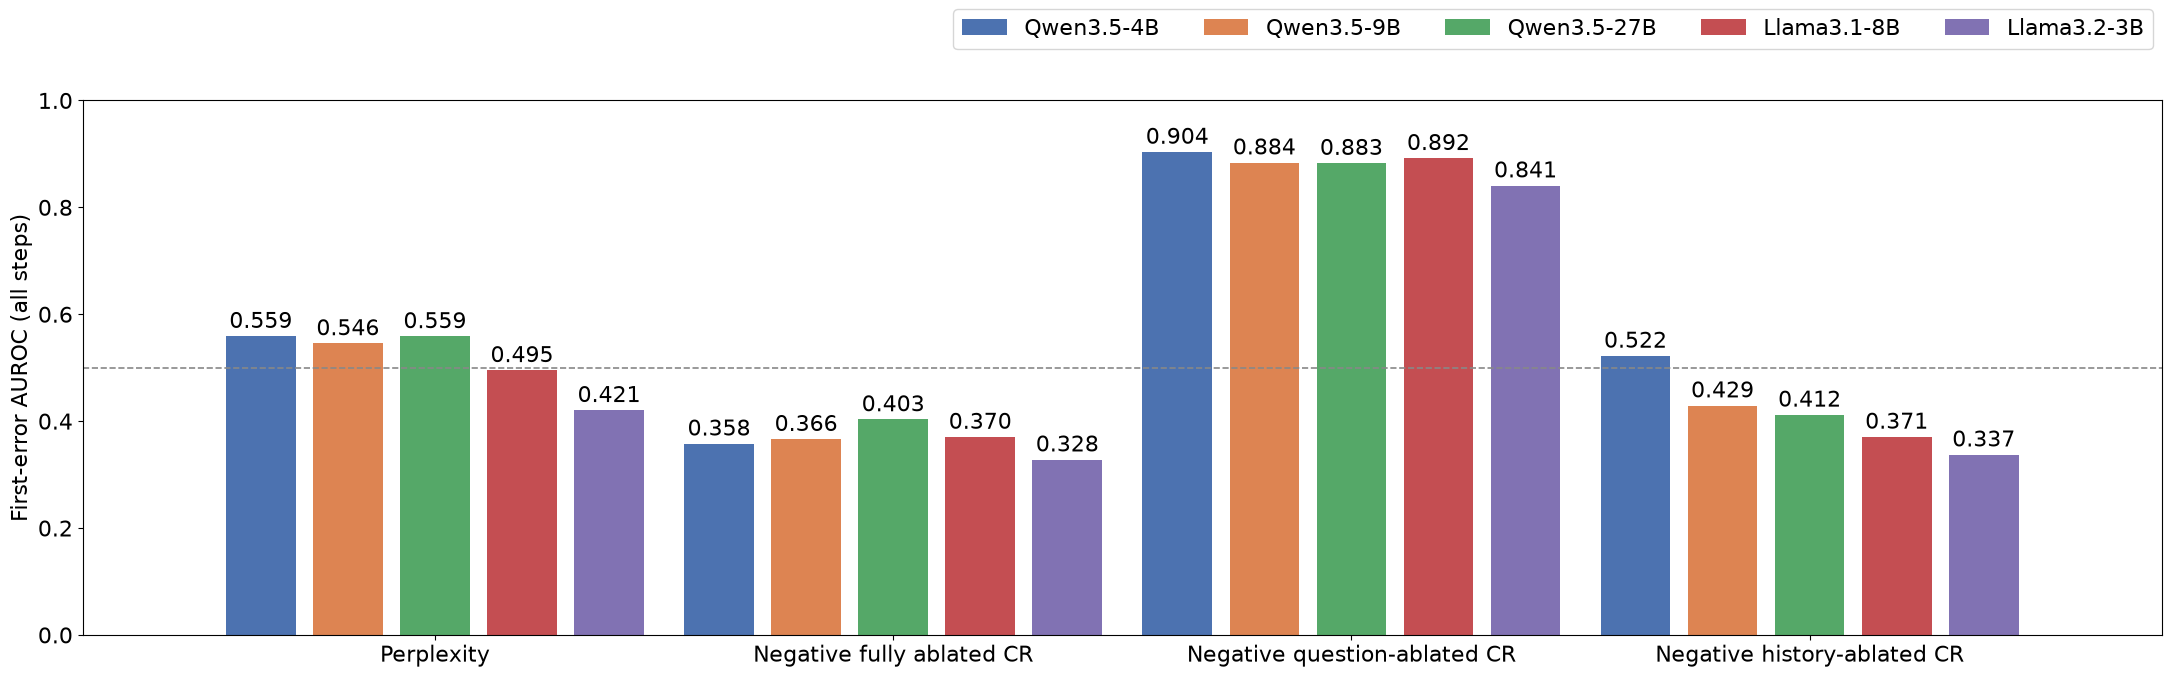

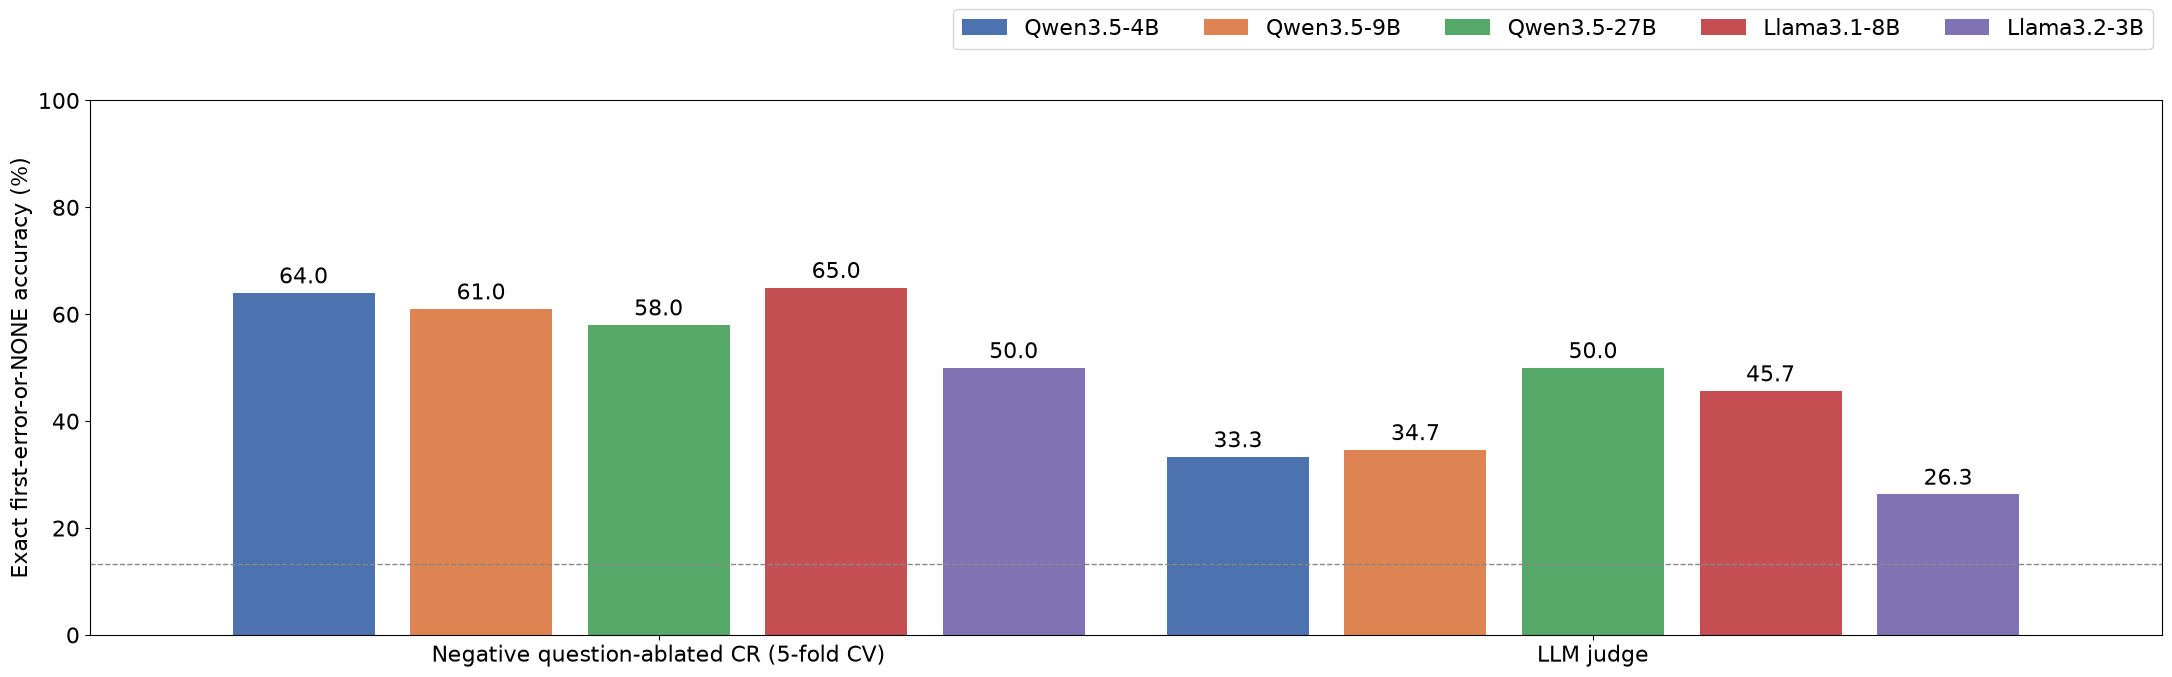

Exported tracking-shuffled-objects-auroc.png and tracking-shuffled-objects-accuracy.png


In [31]:
# Plot the precomputed tracking-shuffled-objects results.
fig, ax = plt.subplots(figsize=(22, 7))
sns.barplot(data=bar_results, x='method', y='auroc', hue='model',
            order=list(bar_methods.values()), hue_order=list(MODELS),
            palette=COLORS, saturation=1, width=.95, gap=.2, errorbar=None, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=TEXT_SIZE, clip_on=False)
ax.axhline(.5, color=PAPER_COLOR, linestyle='--', linewidth=1.2)
ax.set(xlabel='', ylabel='First-error AUROC (all steps)', ylim=(0, 1))
ax.margins(x=.08)
ax.tick_params(axis='both', labelsize=TEXT_SIZE)
ax.tick_params(axis='x', rotation=0)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(.99, .99),
           ncol=5, fontsize=TEXT_SIZE)
fig.tight_layout(rect=(0, 0, 1, .89))
fig.savefig(OUT / 'tracking-shuffled-objects-auroc.png', dpi=220, bbox_inches='tight')
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(22, 7))
sns.barplot(data=accuracy_table.assign(percent=lambda d: 100 * d.accuracy),
            x='method', y='percent', hue='model',
            order=['Negative question-ablated CR (5-fold CV)', 'LLM judge'],
            hue_order=list(MODELS), palette=COLORS, saturation=1,
            width=.95, gap=.2, errorbar=None, ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=TEXT_SIZE, clip_on=False)
ax.axhline(tracking_clean_percent, color=PAPER_COLOR, linestyle='--', linewidth=1)
ax.set(xlabel='', ylabel='Exact first-error-or-NONE accuracy (%)', ylim=(0, 100))
ax.margins(x=.08)
ax.tick_params(axis='both', labelsize=TEXT_SIZE)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(.99, .99),
           ncol=5, fontsize=TEXT_SIZE)
fig.tight_layout(rect=(0, 0, 1, .89))
fig.savefig(OUT / 'tracking-shuffled-objects-accuracy.png', dpi=220, bbox_inches='tight')
display(fig)
plt.close(fig)
print('Exported tracking-shuffled-objects-auroc.png and tracking-shuffled-objects-accuracy.png')

## Appendix: error and matched-control trajectories

Pair each error trace with a clean trace of the same task and length, then plot their scores relative to the matched step position.

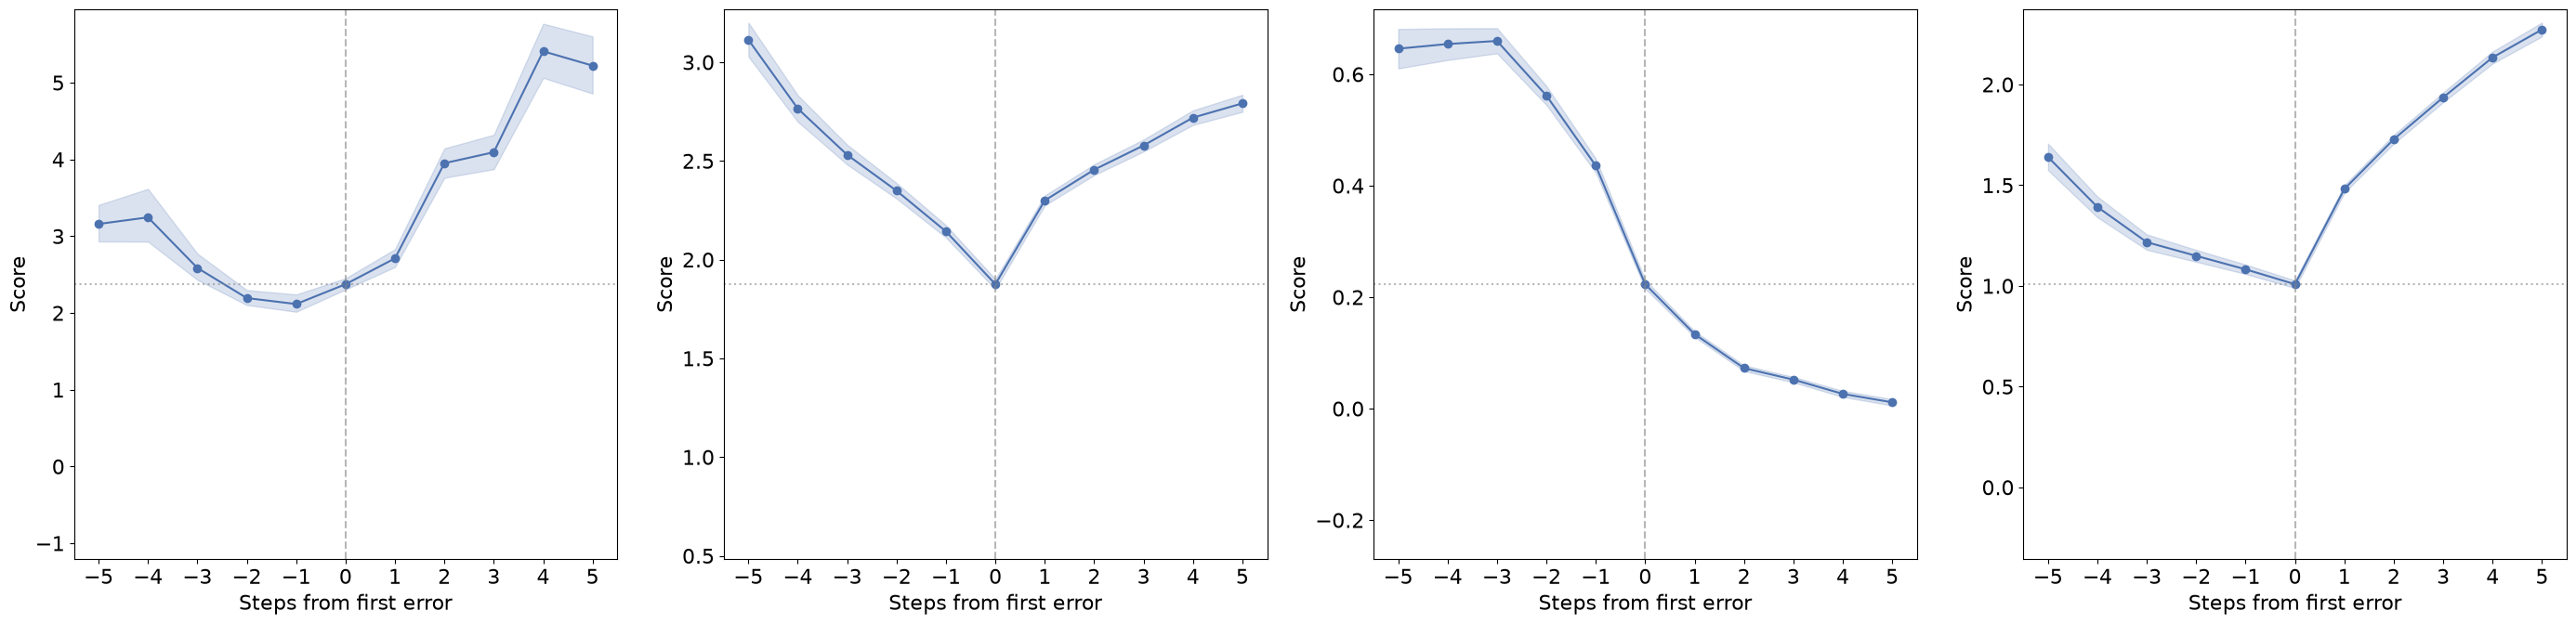

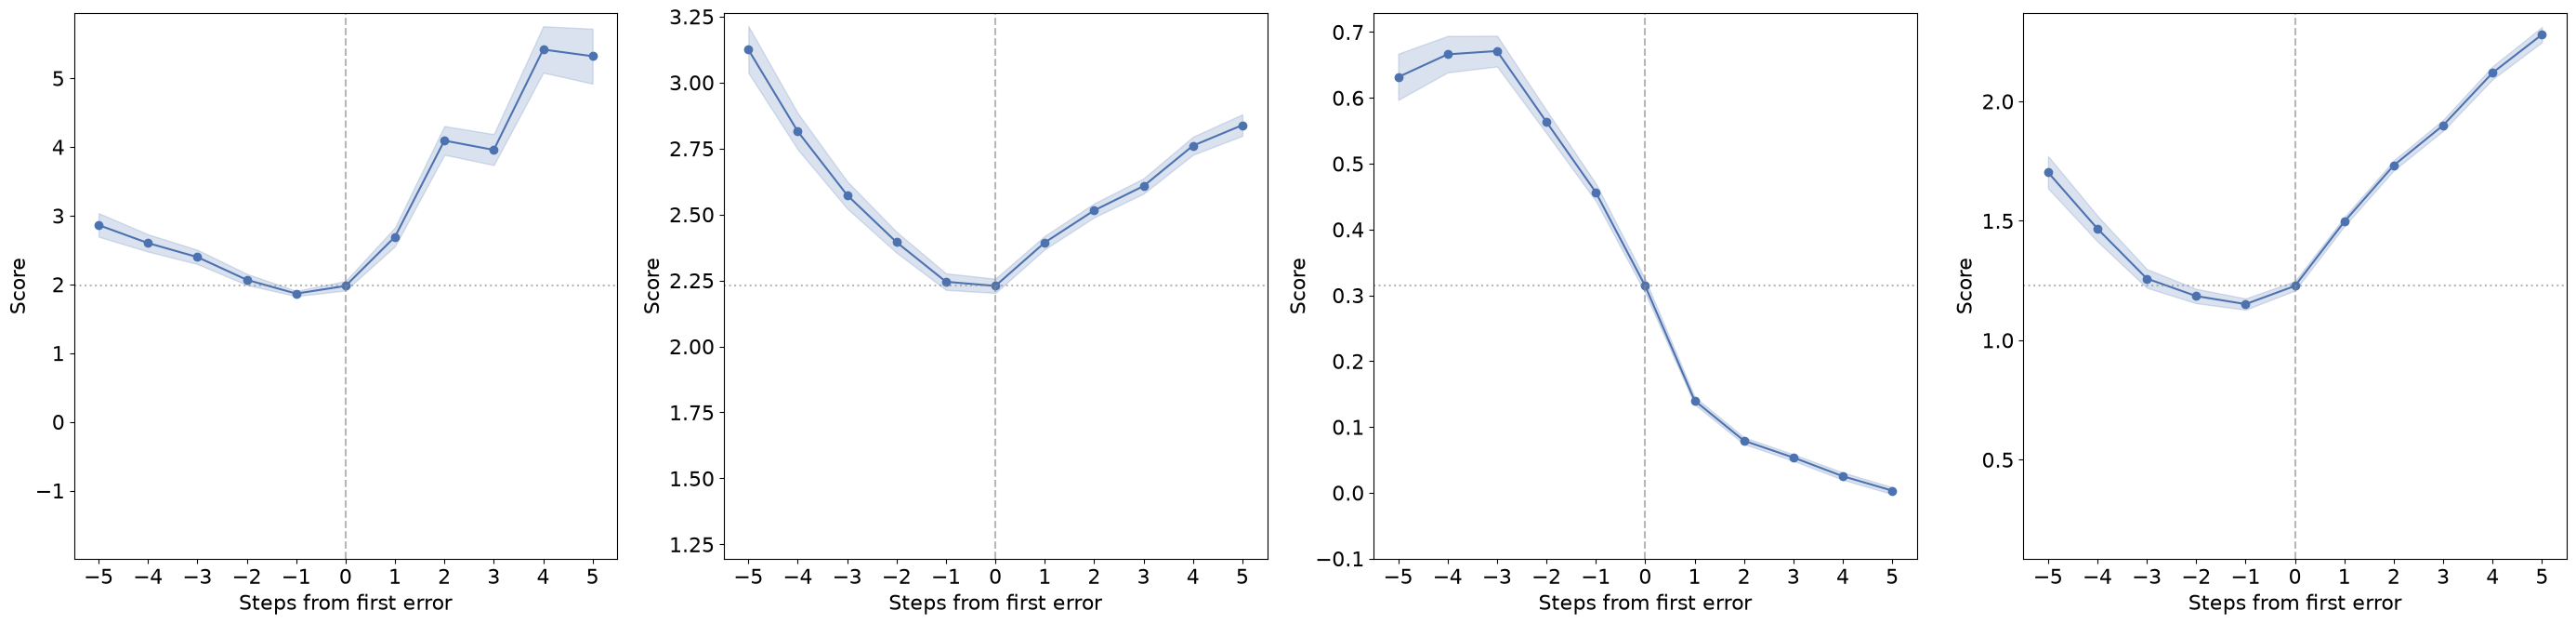

Exported trajectory.png and trajectory-control.png


In [25]:
# Render precomputed mean trajectories and 95% bootstrap confidence intervals.
for filename, summary in trajectory_summaries.items():
    fig, axes = plt.subplots(1, len(dc_pmi.METRICS), figsize=(7 * len(dc_pmi.METRICS), 7),
                             sharex=True, squeeze=False)
    for ax, metric in zip(axes[0], dc_pmi.METRICS):
        values = summary.loc[summary.metric == metric]
        offsets = values.offset.to_numpy()
        ax.plot(offsets, values['mean'].to_numpy(), marker='o', color=OUR_PAPER_COLOR)
        ax.fill_between(offsets, values.ci_low.to_numpy(), values.ci_high.to_numpy(),
                        color=OUR_PAPER_COLOR, alpha=.2)
        first_error_mean = values.loc[values.offset == 0, 'mean'].iloc[0]
        ax.axvline(0, color=PAPER_COLOR, linestyle='--', alpha=.6)
        ax.axhline(first_error_mean, color=PAPER_COLOR, linestyle=':', alpha=.6)
        lower, upper = ax.get_ylim()
        radius = max(first_error_mean - lower, upper - first_error_mean)
        ax.set(xlabel='Steps from first error', ylabel='Score', xticks=range(-5, 6),
               ylim=(first_error_mean - radius, first_error_mean + radius))
        ax.tick_params(axis='both', labelsize=TEXT_SIZE)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=220, bbox_inches='tight')
    display(fig)
    plt.close(fig)
print('Exported trajectory.png and trajectory-control.png')